# 05 · Error vs. noise and horizon

How does accuracy change with sensor quality and with the length of the run? Two sweeps on the random world (5 landmarks, 100 × 100, sensing range 50, steps of 20 units), each value evaluated on the same 20 seeds (0–19):

- **Noise:** motion noise = measurement noise ∈ {0.5, 1, 2, 4, 8}, with N = 20.
- **Horizon:** N ∈ {10, 20, 50, 100, 200}, with noise 2.

Metrics, all against ground truth: pose RMSE over the whole path, final-pose error, landmark RMSE, and the same pose metrics for dead reckoning as a baseline. `scripts/run_sweeps.py` produces the same figures and the per-seed CSV (`assets/sweep_results.csv`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable
ASSETS = Path.cwd().parent / "assets"

import matplotlib.pyplot as plt

import metrics
import viz

KEYS = ("final_pose_err", "pose_rmse", "landmark_rmse", "dr_final_pose_err", "dr_pose_rmse")

def table(summary, name):
    print("%-6s %-14s %-14s %-14s %-14s" % (name, "final pose", "pose RMSE", "landmark RMSE", "DR pose RMSE"))
    for v, d in summary.items():
        print("%-6g " % v + " ".join("%5.2f ± %4.2f  " % d[k] for k in ("final_pose_err", "pose_rmse", "landmark_rmse", "dr_pose_rmse")))

## Noise

noise  final pose     pose RMSE      landmark RMSE  DR pose RMSE  
0.5     0.49 ± 0.19    0.26 ± 0.04    0.21 ± 0.05    1.16 ± 0.33  
1       0.70 ± 0.30    0.51 ± 0.09    0.42 ± 0.10    2.32 ± 0.82  
2       1.55 ± 0.79    1.06 ± 0.21    0.79 ± 0.19    5.02 ± 1.46  
4       3.47 ± 1.35    2.15 ± 0.36    1.63 ± 0.40    9.11 ± 3.21  
8       6.06 ± 3.62    4.44 ± 0.97    3.42 ± 1.04   18.64 ± 5.75  


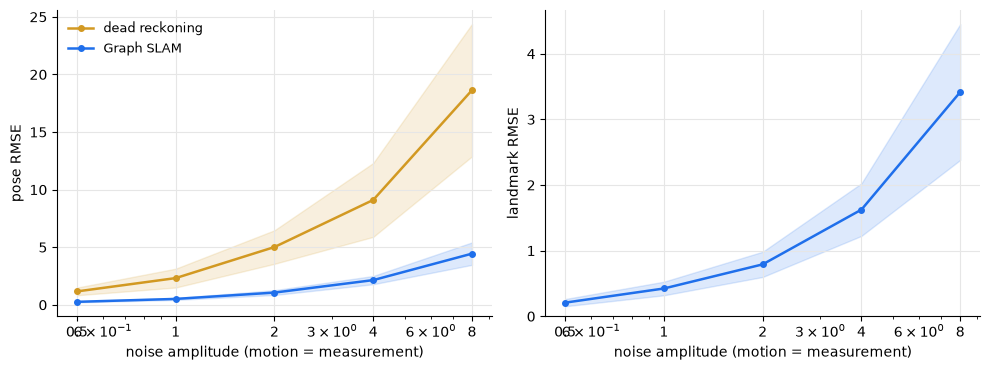

In [2]:
rows_noise = metrics.sweep("noise", [0.5, 1, 2, 4, 8], N=20)
s_noise = metrics.summarize(rows_noise, KEYS)
table(s_noise, "noise")
fig = viz.sweep_figure(s_noise, "noise amplitude (motion = measurement)", logx=True)
fig.savefig(ASSETS / "error_vs_noise.png", dpi=120)
plt.show()

Every error scales roughly linearly with the noise amplitude: doubling the noise doubles pose and landmark RMSE. This is what a linear least-squares estimator should do. The solution is a fixed linear combination of the inputs, so scaling all the input errors scales the output error by the same factor.

The *ratio* to dead reckoning is the interesting number. SLAM's pose RMSE is about 4–5 times lower at every noise level, from 0.26 vs 1.16 at noise 0.5 to 4.44 vs 18.64 at noise 8. The variation across seeds (shaded bands) also grows with the noise and is much wider for dead reckoning, whose error depends on how the individual move errors happen to add up.

## Horizon (N)

N      final pose     pose RMSE      landmark RMSE  DR pose RMSE  
10      2.15 ± 0.88    1.19 ± 0.28    1.01 ± 0.27    3.09 ± 1.05  
20      1.55 ± 0.79    1.06 ± 0.21    0.79 ± 0.19    5.02 ± 1.46  
50      1.84 ± 0.76    1.05 ± 0.15    0.66 ± 0.19    7.54 ± 2.95  
100     1.72 ± 0.84    1.05 ± 0.11    0.61 ± 0.18   10.21 ± 3.90  
200     1.89 ± 0.76    1.03 ± 0.11    0.59 ± 0.19   14.82 ± 4.25  


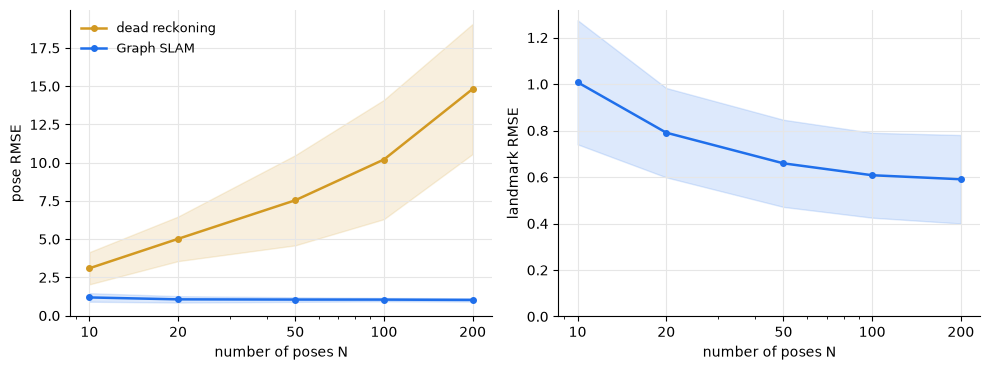

In [3]:
rows_N = metrics.sweep("N", [10, 20, 50, 100, 200], motion_noise=2.0, measurement_noise=2.0)
s_N = metrics.summarize(rows_N, KEYS)
table(s_N, "N")
fig = viz.sweep_figure(s_N, "number of poses N", logx=True)
fig.savefig(ASSETS / "error_vs_N.png", dpi=120)
plt.show()

Running longer affects poses and landmarks differently:

- **Dead reckoning** gets steadily worse, from 3.1 at N = 10 to 14.8 at N = 200. Each move adds an independent error, so the drift behaves like a random walk.
- **SLAM's pose error** stays flat at about 1.05 RMSE (final pose about 1.6–2.2) no matter how long the run is. Each pose is pinned to landmarks it can see, rather than to the chain of moves before it, so the error does not accumulate.
- **Landmark error** keeps improving, from 1.01 at N = 10 to 0.59 at N = 200, because each additional step adds measurements of the same five landmarks. The improvement slows down: from N = 100 to 200 it is only 0.61 → 0.59. Each landmark estimate is limited by the error of the poses it is measured from, which does not shrink.

In this world the robot sees most landmarks most of the time, which is why the pose error does not drift at all. Notebook 04 shows the opposite regime: when landmarks are sparse and the range is short, pose error does build up between observations, until a loop closure brings it back down.